In [1]:
# Pt 4. Regression Model Building Using Random Forest Algorithm
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

In [2]:
# Open the CSV file and read it into a DataFrame
# PubChem fingerprint describes the local feature of the molecule
# While Lepinski describes the global characteristics of the molecules
df = pd.read_csv('bioactivity_XY_dataset.csv')
df.head()  # Display the first few rows of the DataFrame

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880,pIC50
0,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.387216
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,6.769551
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.031517
3,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,3.301030
4,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,2.522879


In [3]:
# Find a way to rearrange molecule to give maximum potency while being safe
X = df.drop('pIC50', axis=1)
X

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
786,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
787,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
788,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
789,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [4]:
Y = df.pIC50
Y

0      7.387216
1      6.769551
2      5.031517
3      3.301030
4      2.522879
         ...   
786    4.000000
787    4.000000
788    4.000000
789    4.000000
790    4.000000
Name: pIC50, Length: 791, dtype: float64

In [5]:
# Find the X data shape
X.shape

(791, 881)

In [6]:
# Find the Ydata shape
Y.shape

(791,)

In [7]:
# Remove low variance features
from sklearn.feature_selection import VarianceThreshold
selection = VarianceThreshold(threshold=(.8 * (1 - .8)))    
X = selection.fit_transform(X)
X.shape

(791, 145)

In [8]:
# Split the data into 80/20 ratio
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2)

In [9]:
X_train.shape, Y_train.shape

((632, 145), (632,))

In [10]:
X_test.shape, Y_test.shape

((159, 145), (159,))

In [11]:
# Building the regression model using random forest

import numpy as np
np.random.seed(100)

model = RandomForestRegressor(n_estimators=100)
model.fit(X_train, Y_train)
r2 = model.score(X_test, Y_test)
r2

0.7036401542562026

In [12]:
Y_pred = model.predict(X_test)

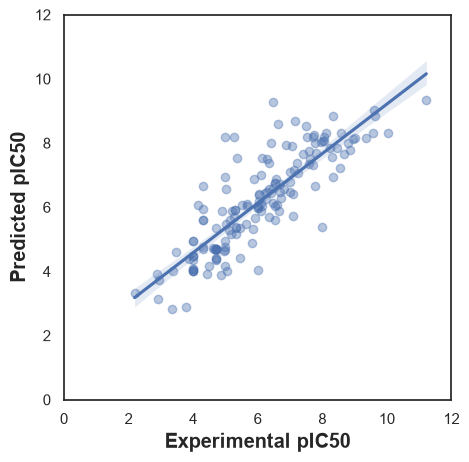

In [14]:
# Scatter Plot of Experimental vs Predicted pIC50 Values
import matplotlib.pyplot as plt

sns.set(color_codes=True)
sns.set_style("white")

ax = sns.regplot(
    x =Y_test,
    y = Y_pred,
    scatter_kws= {"alpha": 0.4}
)

ax.set_xlabel(
    "Experimental pIC50",
    fontsize="large",
    fontweight="bold"
)
ax.set_ylabel(
    "Predicted pIC50",
    fontsize="large",
    fontweight="bold"
)

ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.figure.set_size_inches(5, 5)

plt.show
plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\RegressionForestModel.png",
    dpi=300,
    bbox_inches="tight"
)